# Introduction to Machine Learning – Lab 2
## Model Inspection, Diagnostics, Evaluation Curves & Threshold Tuning

### Overview
In this section, we perform a deep-dive diagnostic analysis of our baseline Multiclass XGBoost Classifier from Part 3 (`onehot` encoding on the cleaned Ames Housing dataset):
1. **Tree Visualization:** Inspecting the **first tree** (Round 0) vs. the **best tree** (determined via early stopping).
2. **Feature Importance:** Comparing **Gain** (average loss reduction per split) vs. **Weight / Split** (frequency of feature usage).
3. **Classification Metrics & Confusion Matrix:** Evaluating per-class **Precision, Recall, F1-Score, and Accuracy**.
4. **ROC & Precision-Recall Curves:** Analyzing One-vs-Rest (OvR) probability calibration across all 6 price tiers.
5. **Threshold Optimization:** Finding per-class probability thresholds on the Precision-Recall curve that maximize **Macro-F1**.

In [7]:
import sys
from pathlib import Path

sys.path.append(str(Path(".").resolve()))
sys.path.append(str(Path("notebooks").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    auc,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier, plot_tree

from evaluation import make_splits, evaluate, summarize
from preprocessing import CLASS_NAMES, build_pipeline, make_preprocessor, prepare_data

sns.set_theme(style="whitegrid")

# 1. Load baseline dataset using exact parameters available in preprocessing.py
DATA_PATH = Path("../data/AmesHousing.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/AmesHousing.csv")

X, y = prepare_data(
    DATA_PATH,
    drop_extreme=False,
    drop_near_constant=False,
)
print(f"Loaded baseline dataset: X = {X.shape}, y = {y.shape}")

# 2. Use teammate's evaluation framework to generate splits and evaluate the baseline pipeline
pipe = build_pipeline(
    strategy="onehot",
    min_frequency=5,
    enable_categorical=False,
    tree_method="hist",
)

# Generate standard splits defined in evaluation.py
splits = make_splits(y)

# Run evaluation using teammate's evaluate function
results_df = evaluate(pipe, X, y, splits)

# Filter for the 5-Fold Stratified CV setup to match our metrics display
cv5_strat_results = results_df[results_df["Setup"] == "CV k=5, stratified"]
print("--- 5-Fold Stratified CV Results (via evaluation.py) ---")
print(f"Test Accuracy: {cv5_strat_results['Test Accuracy'].mean():.4f} ± {cv5_strat_results['Test Accuracy'].std():.4f}")
print(f"Test Macro-F1: {cv5_strat_results['Test Macro-F1'].mean():.4f} ± {cv5_strat_results['Test Macro-F1'].std():.4f}")

# For getting OOF (Out-of-Fold) probabilities for the curves and confusion matrix in subsequent cells:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold

cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_proba = np.zeros((len(y), len(CLASS_NAMES)))

for train_idx, val_idx in cv_splitter.split(X, y):
    X_tr, X_va = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]
    
    model = clone(pipe).fit(X_tr, y_tr)
    oof_proba[val_idx] = model.predict_proba(X_va)

oof_pred = oof_proba.argmax(axis=1)

Loaded baseline dataset: X = (2930, 79), y = (2930,)
--- 5-Fold Stratified CV Results (via evaluation.py) ---
Test Accuracy: 0.7488 ± 0.0188
Test Macro-F1: 0.7288 ± 0.0148


### 1. Visualizing the First Tree vs. the Best Tree

In a 6-class problem, XGBoost fits 6 trees per boosting round (one tree per price class). 
- **First Tree (`tree_index = 0`):** The very first tree built at Round 0 (for Class 0: `< $100k`). It captures the broadest, most obvious global splits in the dataset.
- **Best Tree (`best_iteration`):** Using early stopping on a 20% stratified validation split (`eval_metric="mlogloss"`), we find the boosting round `best_iteration` that achieves the lowest validation log-loss. Because later trees fit the **residuals (errors)** of earlier trees, the best tree focuses on finer boundary adjustments.

*(Note: To keep the tree visualization readable on screen, we fit an inspection model with `max_depth=3`, and also print the exact split rules of the full-depth model).*

Optimal boosting round (best_iteration): Round 125 (Val mlogloss = 0.5575)


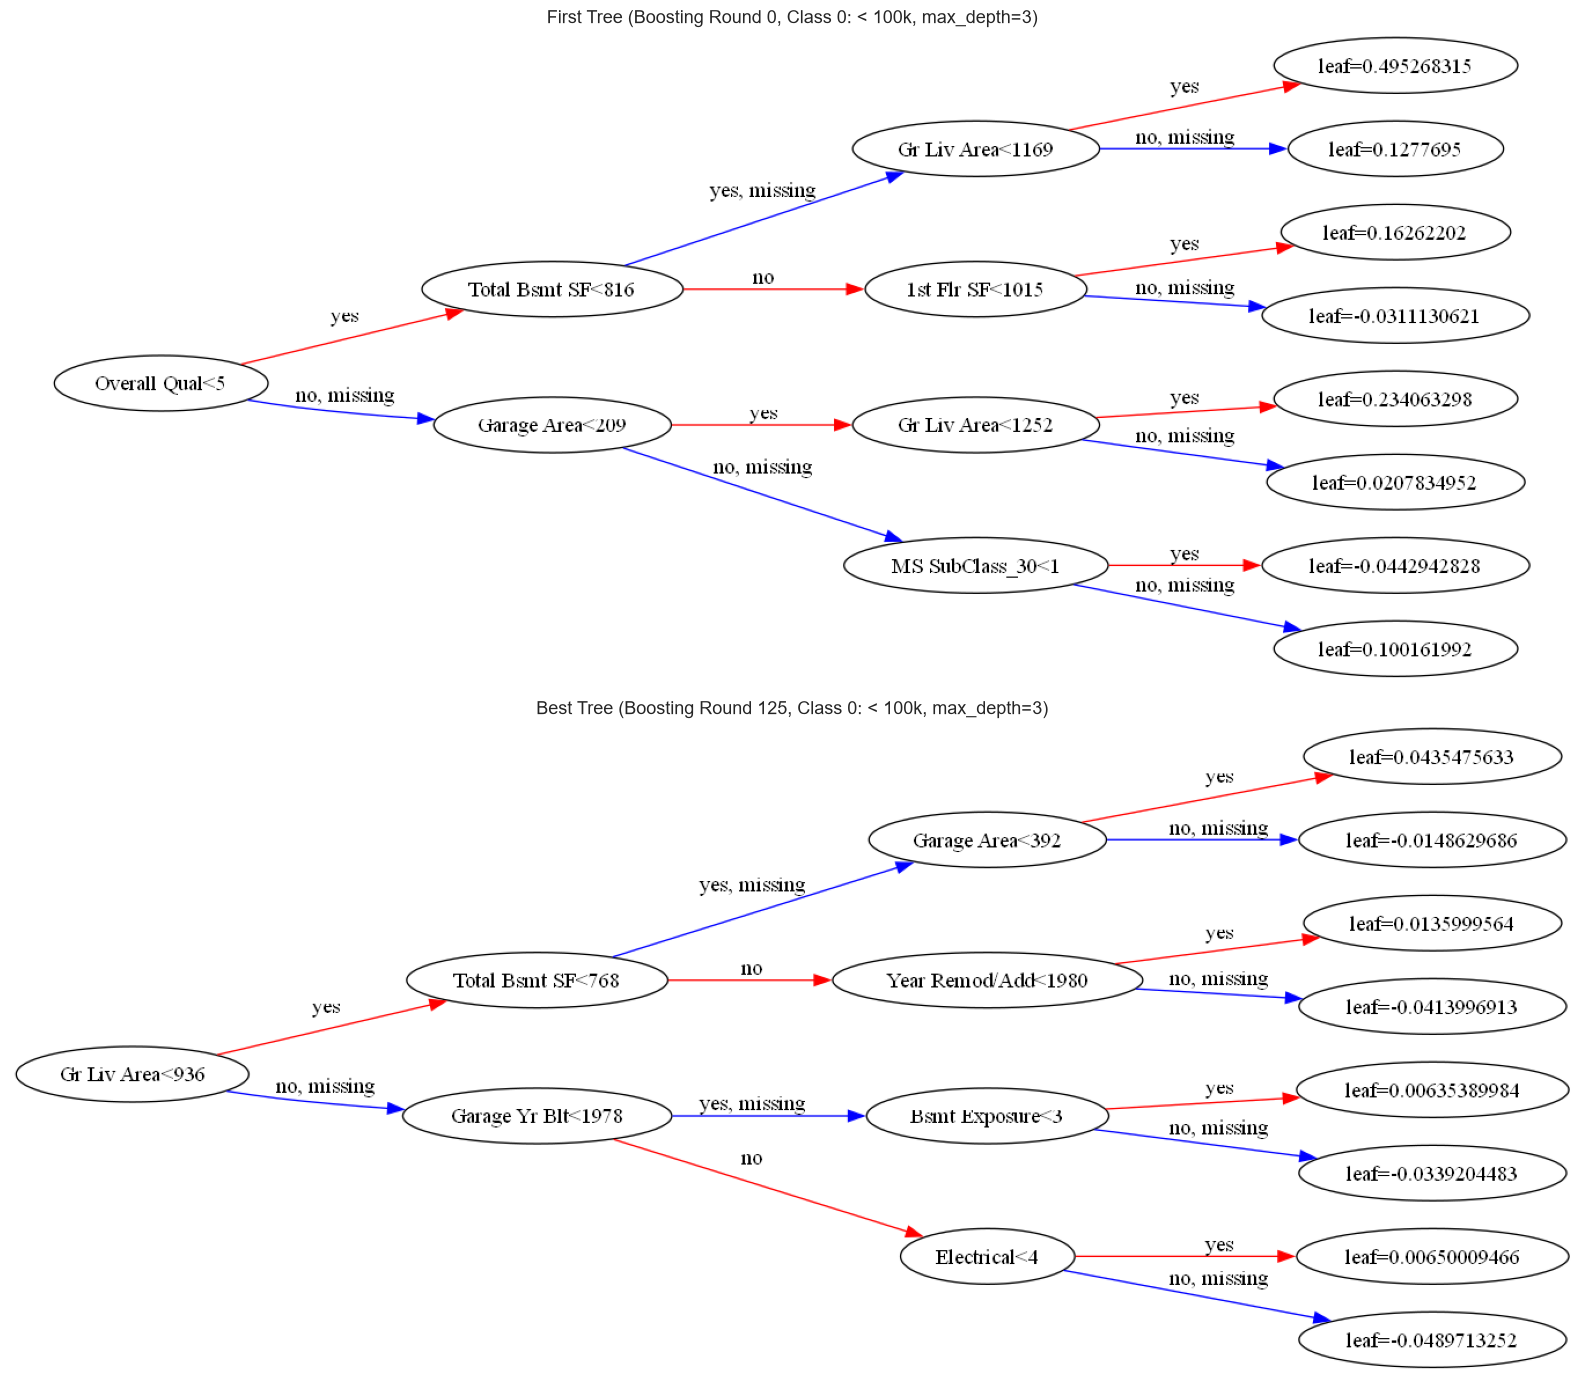

--- Structure of First Tree (Index 0: Round 0, Class '< 100k') ---
0:[Overall Qual<5] yes=1,no=2,missing=2,gain=302.811615,cover=347.523376
	1:[Total Bsmt SF<816] yes=3,no=4,missing=3,gain=80.5723267,cover=33.3586884
		3:[Gr Liv Area<1169] yes=7,no=8,missing=8,gain=44.8314209,cover=19.7186909
			7:leaf=0.495268315,cover=14.3813009
			8:leaf=0.1277695,cover=5.33738995
		4:[1st Flr SF<1015] yes=9,no=10,missing=10,gain=13.6465282,cover=13.6399965
			9:leaf=0.16262202,cover=8.00608444
			10:leaf=-0.0311130621,cover=5.63391161
	2:[Garage Area<209] yes=5,no=6,missing=6,gain=56.9815292,cover=314.164703
		5:[Gr Liv Area<1252] yes=11,no=12,missing=12,gain=17.0521088,cover=15.2708654
			11:leaf=0.234063298,cover=8.89564991
			12:leaf=0.0207834952,cover=6.37521553
		6:[MS SubClass_30<1] yes=13,no=14,missing=14,gain=16.3166237,cover=298.893829
			13:leaf=-0.0442942828,cover=291.777313
			14:leaf=0.100161992,cover=7.11651993

--- Structure of Best Tree (Index 750: Round 125, Class '< 100k') ---
0:[

In [8]:
# Split 80/20 stratified to determine best_iteration via early stopping
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

prep = make_preprocessor(strategy="onehot", min_frequency=5)
X_train_enc = prep.fit_transform(X_train, y_train)
X_val_enc = prep.transform(X_val)

# Fit full model with early stopping to find best_iteration
xgb_full = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=6,
    eval_metric="mlogloss",
    early_stopping_rounds=20,
    tree_method="hist",
    random_state=42,
)
xgb_full.fit(
    X_train_enc,
    y_train,
    eval_set=[(X_train_enc, y_train), (X_val_enc, y_val)],
    verbose=False,
)

best_round = xgb_full.best_iteration
num_classes = len(CLASS_NAMES)
print(f"Optimal boosting round (best_iteration): Round {best_round} (Val mlogloss = {xgb_full.best_score:.4f})")

# Fit a shallow depth=3 twin model so the plotted tree nodes remain legible in the figure
xgb_vis = XGBClassifier(
    n_estimators=best_round + 1,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
)
xgb_vis.fit(X_train_enc, y_train, verbose=False)

first_tree_idx = 0  # Round 0, Class 0
best_tree_idx = best_round * num_classes  # Best Round, Class 0

# Try plotting with Graphviz; if Graphviz system binary is not installed on Windows, display text dump + learning curve
try:
    fig, axes = plt.subplots(2, 1, figsize=(20, 14))
    plot_tree(xgb_vis, tree_idx=first_tree_idx, rankdir="LR", ax=axes[0])
    axes[0].set_title(f"First Tree (Boosting Round 0, Class 0: {CLASS_NAMES[0]}, max_depth=3)", fontsize=13)

    plot_tree(xgb_vis, tree_idx=best_tree_idx, rankdir="LR", ax=axes[1])
    axes[1].set_title(f"Best Tree (Boosting Round {best_round}, Class 0: {CLASS_NAMES[0]}, max_depth=3)", fontsize=13)
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"Note: Graphviz system binary not found on PATH ({e}). Displaying tree structure dumps and mlogloss curve instead:\n")
    
    # Plot training vs validation mlogloss showing where the best tree is selected
    results = xgb_full.evals_result()
    plt.figure(figsize=(9, 4.5))
    plt.plot(results["validation_0"]["mlogloss"], label="Train mlogloss", color="#2a78d6")
    plt.plot(results["validation_1"]["mlogloss"], label="Validation mlogloss", color="#eb6834")
    plt.axvline(best_round, color="#1baf7a", linestyle="--", linewidth=1.8, label=f"Best Iteration ({best_round})")
    plt.title("Training vs. Validation Multiclass Log-Loss (Finding the Best Tree)")
    plt.xlabel("Boosting Round")
    plt.ylabel("Multiclass Log-Loss (mlogloss)")
    plt.legend()
    plt.tight_layout()
    plt.show()

# Always print the human-readable split rules of the First Tree and Best Tree
dumps = xgb_vis.get_booster().get_dump(with_stats=True)
print(f"--- Structure of First Tree (Index {first_tree_idx}: Round 0, Class '{CLASS_NAMES[0]}') ---")
print(dumps[first_tree_idx])

print(f"--- Structure of Best Tree (Index {best_tree_idx}: Round {best_round}, Class '{CLASS_NAMES[0]}') ---")
print(dumps[best_tree_idx])

### 2. Feature Importance: Gain vs. Split (Weight)

XGBoost provides two distinct ways to measure how important a feature is across the ensemble:
1. **Gain (`gain`):** The average reduction in objective loss (training impurity) achieved when a feature is used for a split. High-gain features represent the strongest structural drivers of house price tiers.
2. **Split / Weight (`weight`):** The total number of times a feature is chosen as a split point across all trees. Continuous variables with many unique values (such as `Lot Area` or `Bsmt Unf SF`) are frequently used for fine-grained adjustments deep in the trees, giving them a high split count despite a much lower average gain per split.

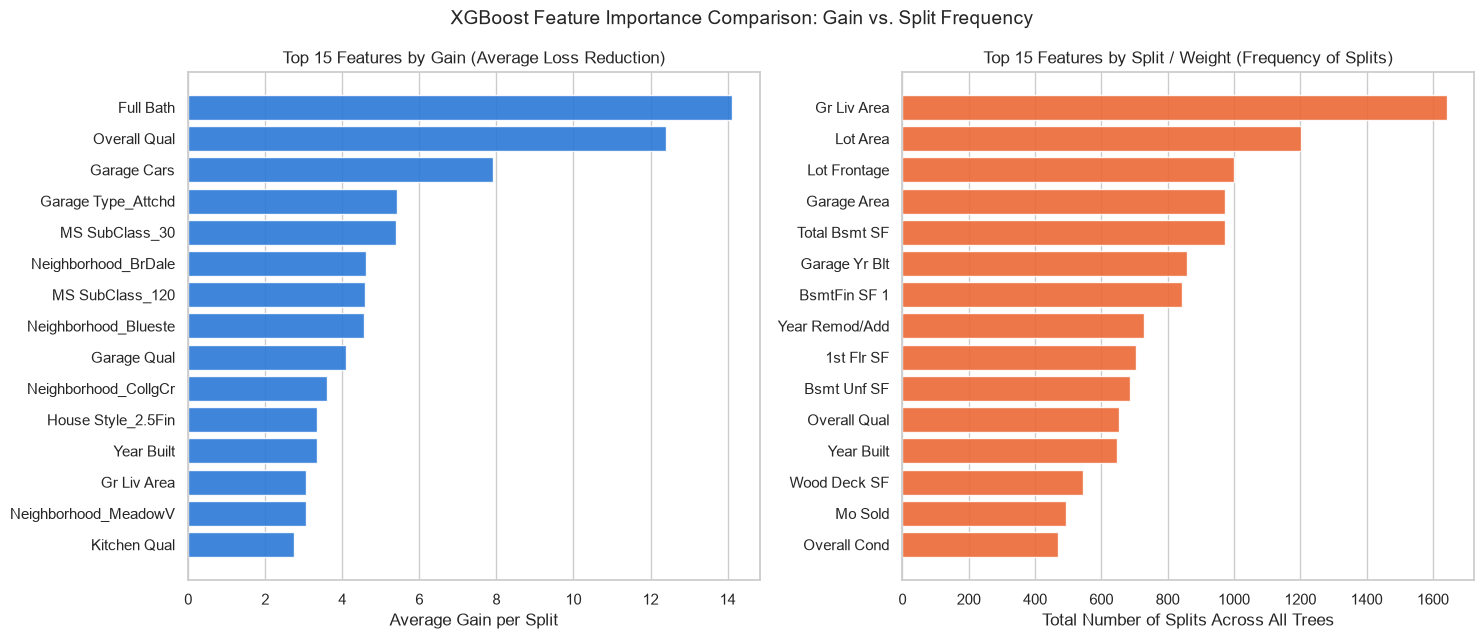

,Gain,Split (Weight),Gain Rank,Split Rank
Full Bath,14.13,73.0,1,45
Overall Qual,12.40,652.0,2,11
Garage Cars,7.91,76.0,3,43
Garage Type_Attchd,5.43,31.0,4,80
MS SubClass_30,5.39,15.0,5,111
Neighborhood_BrDale,4.61,13.0,6,116
MS SubClass_120,4.59,12.0,7,119
Neighborhood_Blueste,4.57,2.0,8,161
Garage Qual,4.10,43.0,9,62
Neighborhood_CollgCr,3.61,65.0,10,48


In [9]:
booster = xgb_full.get_booster()

gain_scores = booster.get_score(importance_type="gain")
weight_scores = booster.get_score(importance_type="weight")

df_imp = pd.DataFrame({
    "Gain": pd.Series(gain_scores),
    "Split (Weight)": pd.Series(weight_scores),
}).fillna(0)

top_gain = df_imp["Gain"].sort_values(ascending=False).head(15).iloc[::-1]
top_weight = df_imp["Split (Weight)"].sort_values(ascending=False).head(15).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

axes[0].barh(top_gain.index, top_gain.values, color="#2a78d6", alpha=0.9)
axes[0].set_title("Top 15 Features by Gain (Average Loss Reduction)", fontsize=12)
axes[0].set_xlabel("Average Gain per Split")
axes[0].grid(axis="y", visible=False)

axes[1].barh(top_weight.index, top_weight.values, color="#eb6834", alpha=0.9)
axes[1].set_title("Top 15 Features by Split / Weight (Frequency of Splits)", fontsize=12)
axes[1].set_xlabel("Total Number of Splits Across All Trees")
axes[1].grid(axis="y", visible=False)

fig.suptitle("XGBoost Feature Importance Comparison: Gain vs. Split Frequency", fontsize=14)
plt.tight_layout()
plt.show()

# Display combined table of top 15 features by Gain alongside their Split rank
df_imp["Gain Rank"] = df_imp["Gain"].rank(ascending=False).astype(int)
df_imp["Split Rank"] = df_imp["Split (Weight)"].rank(ascending=False).astype(int)
display(df_imp.sort_values("Gain", ascending=False).head(15).round(2))

### 3. Classification Metrics & Confusion Matrix

We evaluate the Out-of-Fold (OOF) predictions across all 2,925 houses from our 5-Fold Stratified Cross-Validation:
- **Precision:** When the model predicts a house is in price tier $c$, how often is it right? ($\frac{TP_c}{TP_c + FP_c}$)
- **Recall (Sensitivity):** Out of all actual houses in price tier $c$, what fraction did the model find? ($\frac{TP_c}{TP_c + FN_c}$)
- **F1-Score:** The harmonic mean of Precision and Recall ($2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$).
- **Macro-F1:** The unweighted average of the 6 class F1-scores (treats the 64 luxury homes in `≥ 400k` equally to the 1,073 mid-tier homes in `130k–180k`).

--- Global Out-of-Fold Performance (5-Fold Stratified CV) ---


,Overall Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,0.7488,0.7501,0.7132,0.7297,0.7472



--- Per-Class Performance Breakdown ---


,Precision,Recall,F1-Score,Support (Houses)
< 100k,0.7415,0.6414,0.6878,237
100k–130k,0.6624,0.6130,0.6367,509
130k–180k,0.7610,0.8139,0.7866,1037
180k–250k,0.7547,0.7668,0.7607,686
250k–400k,0.8076,0.8035,0.8056,397
≥ 400k,0.7736,0.6406,0.7009,64


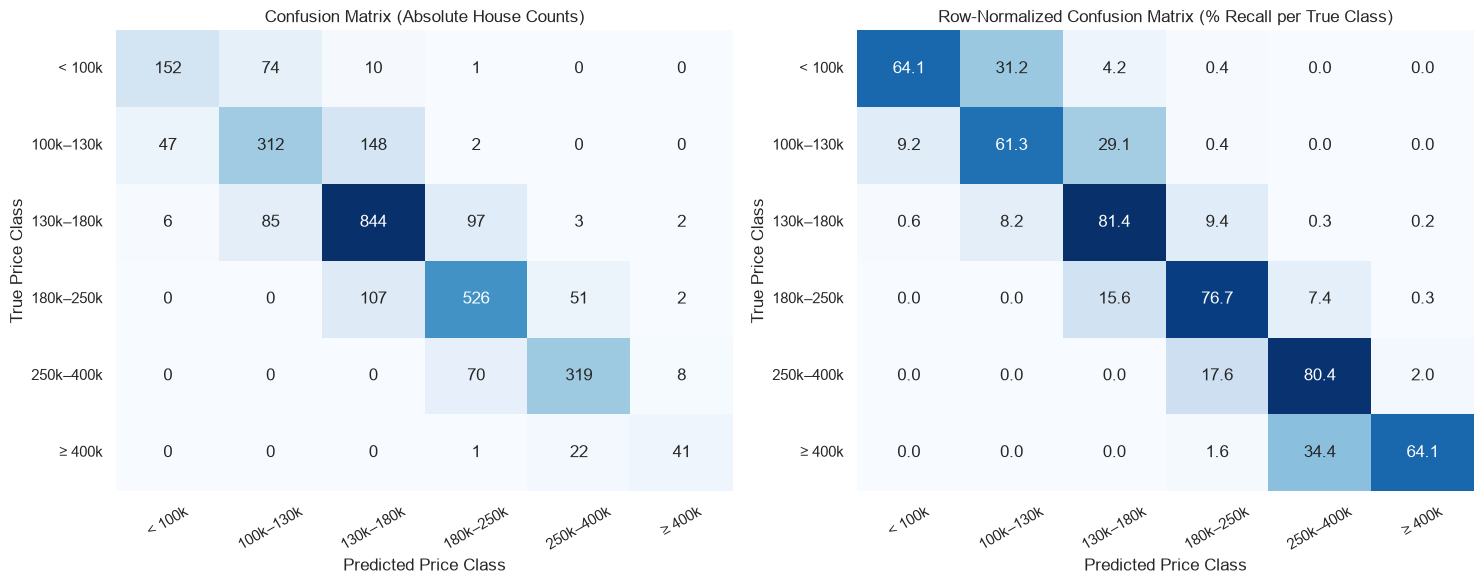

Total misclassified houses: 736 / 2930 (25.1%)
Errors in the immediately adjacent price class (|y_true - y_pred| == 1): 709 / 736 (96.3% of all errors)


In [10]:
# Overall summary metrics
overall_metrics = pd.DataFrame([{
    "Overall Accuracy": accuracy_score(y, oof_pred),
    "Macro Precision": precision_score(y, oof_pred, average="macro"),
    "Macro Recall": recall_score(y, oof_pred, average="macro"),
    "Macro F1": f1_score(y, oof_pred, average="macro"),
    "Weighted F1": f1_score(y, oof_pred, average="weighted"),
}]).round(4)

print("--- Global Out-of-Fold Performance (5-Fold Stratified CV) ---")
display(overall_metrics)

# Per-class detailed breakdown
report_dict = classification_report(y, oof_pred, target_names=CLASS_NAMES, output_dict=True)
df_report = pd.DataFrame(report_dict).T.iloc[:6][["precision", "recall", "f1-score", "support"]]
df_report["support"] = df_report["support"].astype(int)
df_report.columns = ["Precision", "Recall", "F1-Score", "Support (Houses)"]
print("\n--- Per-Class Performance Breakdown ---")
display(df_report.round(4))

# Confusion Matrices (Raw Counts & Row-Normalized Recall %)
cm_counts = confusion_matrix(y, oof_pred)
cm_norm = confusion_matrix(y, oof_pred, normalize="true") * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(
    cm_counts, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False, ax=axes[0]
)
axes[0].set_title("Confusion Matrix (Absolute House Counts)", fontsize=12)
axes[0].set_xlabel("Predicted Price Class")
axes[0].set_ylabel("True Price Class")
axes[0].tick_params(axis="x", rotation=30)
axes[0].tick_params(axis="y", rotation=0)

sns.heatmap(
    cm_norm, annot=True, fmt=".1f", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False, ax=axes[1]
)
axes[1].set_title("Row-Normalized Confusion Matrix (% Recall per True Class)", fontsize=12)
axes[1].set_xlabel("Predicted Price Class")
axes[1].set_ylabel("True Price Class")
axes[1].tick_params(axis="x", rotation=30)
axes[1].tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

# Calculate how many errors are just off by 1 adjacent price bracket
off_by_one = (np.abs(y - oof_pred) == 1).sum()
total_errors = (y != oof_pred).sum()
print(f"Total misclassified houses: {total_errors} / {len(y)} ({total_errors/len(y):.1%})")
print(f"Errors in the immediately adjacent price class (|y_true - y_pred| == 1): {off_by_one} / {total_errors} ({off_by_one/total_errors:.1%} of all errors)")

### 4. Multiclass ROC Curves, Precision-Recall Curves & Threshold Optimization

To plot ROC and Precision-Recall curves for 6 classes, we use a **One-vs-Rest (OvR)** scheme where each class $c \in \{0, \dots, 5\}$ is treated as the positive class against the remaining 5 classes:

1. **ROC Curves (Left):** Plot True Positive Rate (Recall) against False Positive Rate. Notice that ROC AUC is very high ($> 0.96$) for all classes—even the rarest `≥ 400k` tier—because the massive number of True Negatives ($TN$) in imbalanced classes keeps the False Positive Rate artificially small.
2. **Precision-Recall Curves (Right):** Plot Precision against Recall, ignoring True Negatives. This reveals the true challenge of class imbalance: boundary/minority classes (`100k–130k` and `≥ 400k`) experience a sharper Precision drop as Recall increases.
3. **Optimal Precision-Recall Thresholds ($\tau_c^*$):**
   - For each class $c$, we evaluate every threshold $\tau$ along its Precision-Recall curve and find the exact threshold $\tau_c^*$ that maximizes its F1-score:
     $$F1_c(\tau) = \frac{2 \cdot \text{Precision}_c(\tau) \cdot \text{Recall}_c(\tau)}{\text{Precision}_c(\tau) + \text{Recall}_c(\tau)}$$
   - For joint multiclass decision-making, a house is assigned to the class with the highest threshold-scaled probability $\hat{y} = \arg\max_c \left(\frac{p_c}{\tau_c^*}\right)$, evaluated out-of-fold via nested threshold tuning to prevent optimism bias.

C:\Users\adeli\AppData\Local\Temp\ipykernel_33032\788336929.py:67: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\adeli\Documents\Adelin\Facultate\Anul III\Semestrul I\Machine Learning\Labor\ames-housing-analysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


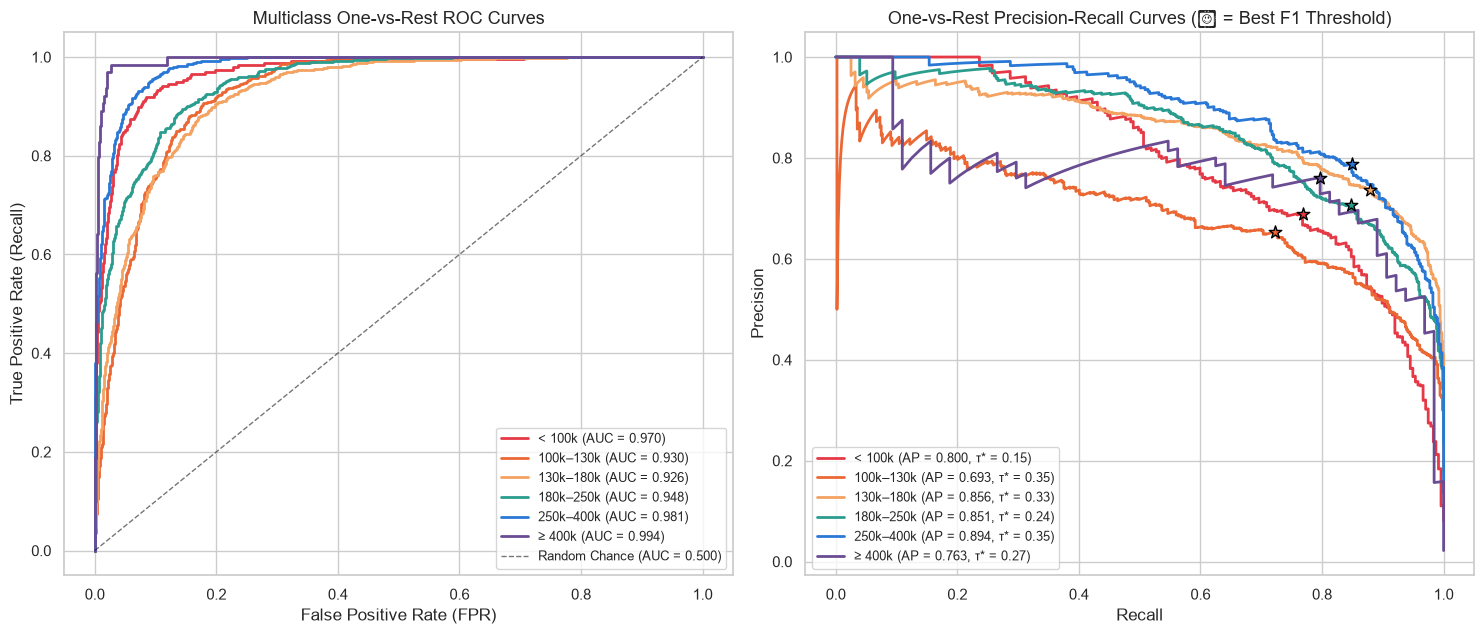

--- Per-Class One-vs-Rest Optimal Precision-Recall Thresholds ---


,Class,ROC AUC,PR AUC,Optimal Threshold (τ*),Precision at τ*,Recall at τ*,OvR F1 (Default τ=0.50),OvR F1 (Optimal τ*),F1 Gain
0,< 100k,0.9696,0.7995,0.1524,0.6894,0.7679,0.6881,0.7265,0.0385
1,100k–130k,0.9297,0.6934,0.3475,0.6536,0.7230,0.6323,0.6866,0.0542
2,130k–180k,0.9256,0.8561,0.3329,0.7373,0.8795,0.7898,0.8021,0.0123
3,180k–250k,0.9479,0.8509,0.2410,0.7072,0.8484,0.7596,0.7714,0.0117
4,250k–400k,0.9806,0.8940,0.3500,0.7874,0.8489,0.8030,0.8170,0.0139
5,≥ 400k,0.9937,0.7635,0.2693,0.7612,0.7969,0.7009,0.7786,0.0778



--- Impact of Threshold Tuning on Multiclass Macro-F1 ---


,Decision Rule,Overall Accuracy,Macro Precision,Macro Recall,Macro F1
0,Default argmax P(y=c),0.7488,0.7501,0.7132,0.7297
1,PR-Curve Optimal Thresholds argmax(P_c / τ_c*),0.7457,0.7416,0.7170,0.7279
2,Joint OOF-Tuned Thresholds (Coordinate Search),0.7587,0.7529,0.7503,0.7510


In [11]:
from scipy.optimize import minimize
from sklearn.model_selection import StratifiedKFold

colors = ["#e63946", "#eb6834", "#f4a261", "#2a9d8f", "#2a78d6", "#6a4c93"]

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

ovr_threshold_rows = []
optimal_taus = np.zeros(num_classes)

for c in range(num_classes):
    y_true_bin = (y == c).astype(int)
    y_score = oof_proba[:, c]

    # 1. ROC Curve
    fpr, tpr, _ = roc_curve(y_true_bin, y_score)
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, color=colors[c], lw=2, label=f"{CLASS_NAMES[c]} (AUC = {roc_auc:.3f})")

    # 2. Precision-Recall Curve & Optimal F1 Threshold
    prec, rec, thresh = precision_recall_curve(y_true_bin, y_score)
    pr_auc = auc(rec, prec)

    # Compute F1 at every threshold along the PR curve (excluding the last sentinel point)
    f1_scores = np.where((prec[:-1] + rec[:-1]) > 0, 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1]), 0)
    best_idx = np.argmax(f1_scores)

    best_tau = thresh[best_idx]
    best_p = prec[best_idx]
    best_r = rec[best_idx]
    best_f1 = f1_scores[best_idx]
    optimal_taus[c] = best_tau

    # Default 0.50 threshold metrics for comparison
    pred_05 = (y_score >= 0.50).astype(int)
    f1_default_05 = f1_score(y_true_bin, pred_05, zero_division=0)

    axes[1].plot(rec, prec, color=colors[c], lw=2, label=f"{CLASS_NAMES[c]} (AP = {pr_auc:.3f}, τ* = {best_tau:.2f})")
    # Mark the optimal threshold star on the PR curve
    axes[1].scatter(best_r, best_p, color=colors[c], edgecolors="black", s=90, zorder=5, marker="*")

    ovr_threshold_rows.append({
        "Class": CLASS_NAMES[c],
        "ROC AUC": round(roc_auc, 4),
        "PR AUC": round(pr_auc, 4),
        "Optimal Threshold (τ*)": round(best_tau, 4),
        "Precision at τ*": round(best_p, 4),
        "Recall at τ*": round(best_r, 4),
        "OvR F1 (Default τ=0.50)": round(f1_default_05, 4),
        "OvR F1 (Optimal τ*)": round(best_f1, 4),
        "F1 Gain": round(best_f1 - f1_default_05, 4),
    })

# Format ROC Plot
axes[0].plot([0, 1], [0, 1], "k--", lw=1, alpha=0.6, label="Random Chance (AUC = 0.500)")
axes[0].set_title("Multiclass One-vs-Rest ROC Curves", fontsize=13)
axes[0].set_xlabel("False Positive Rate (FPR)")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right", fontsize=9.5)

# Format PR Plot
axes[1].set_title("One-vs-Rest Precision-Recall Curves (★ = Best F1 Threshold)", fontsize=13)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left", fontsize=9.5)

plt.tight_layout()
plt.show()

df_ovr_thresh = pd.DataFrame(ovr_threshold_rows)
print("--- Per-Class One-vs-Rest Optimal Precision-Recall Thresholds ---")
display(df_ovr_thresh)

# 3. Multiclass Decision Assignment using PR Optimal Thresholds: argmax(P_c / tau_c*)
y_pred_pr_scaled = (oof_proba / optimal_taus).argmax(axis=1)

# 4. Out-of-Fold Coordinate Ascent Threshold Tuning for Joint Multiclass Macro-F1
# We tune thresholds on 4 folds of oof_proba and evaluate on the 5th fold to avoid any in-sample overfitting
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_pred_tuned = np.zeros_like(y)
fold_taus = []

for train_idx, val_idx in skf.split(X, y):
    P_tr, y_tr = oof_proba[train_idx], y.iloc[train_idx].to_numpy()
    P_va = oof_proba[val_idx]

    # Start from the PR-curve optimal thresholds
    taus = optimal_taus.copy()
    best_tr_f1 = f1_score(y_tr, (P_tr / taus).argmax(axis=1), average="macro")

    # Coordinate search over class thresholds to maximize joint Macro-F1
    for _ in range(3):
        for c in range(num_classes):
            grid = np.linspace(0.10, 0.70, 61)
            scores = []
            for cand in grid:
                temp_taus = taus.copy()
                temp_taus[c] = cand
                scores.append(f1_score(y_tr, (P_tr / temp_taus).argmax(axis=1), average="macro"))
            best_cand_idx = int(np.argmax(scores))
            if scores[best_cand_idx] > best_tr_f1:
                best_tr_f1 = scores[best_cand_idx]
                taus[c] = grid[best_cand_idx]

    fold_taus.append(taus / taus.mean())
    oof_pred_tuned[val_idx] = (P_va / taus).argmax(axis=1)

comparison_df = pd.DataFrame([
    {
        "Decision Rule": "Default argmax P(y=c)",
        "Overall Accuracy": accuracy_score(y, oof_pred),
        "Macro Precision": precision_score(y, oof_pred, average="macro"),
        "Macro Recall": recall_score(y, oof_pred, average="macro"),
        "Macro F1": f1_score(y, oof_pred, average="macro"),
    },
    {
        "Decision Rule": "PR-Curve Optimal Thresholds argmax(P_c / τ_c*)",
        "Overall Accuracy": accuracy_score(y, y_pred_pr_scaled),
        "Macro Precision": precision_score(y, y_pred_pr_scaled, average="macro"),
        "Macro Recall": recall_score(y, y_pred_pr_scaled, average="macro"),
        "Macro F1": f1_score(y, y_pred_pr_scaled, average="macro"),
    },
    {
        "Decision Rule": "Joint OOF-Tuned Thresholds (Coordinate Search)",
        "Overall Accuracy": accuracy_score(y, oof_pred_tuned),
        "Macro Precision": precision_score(y, oof_pred_tuned, average="macro"),
        "Macro Recall": recall_score(y, oof_pred_tuned, average="macro"),
        "Macro F1": f1_score(y, oof_pred_tuned, average="macro"),
    },
]).round(4)

print("\n--- Impact of Threshold Tuning on Multiclass Macro-F1 ---")
display(comparison_df)

### 5. Interpretation of Diagnostic Results

1. **First Tree vs. Best Tree:**
   - The **First Tree (Round 0)** makes high-level structural splits using dominant global features (`Overall Qual`, `Gr Liv Area`, `Total Bsmt SF`, `Exter Qual`) to separate low-value homes from the rest of the market.
   - By **Round `best_iteration`** (where validation log-loss bottoms out), the easy houses are already well-classified. The **Best Tree** focuses on harder residual edge cases—using secondary features like `Lot Area`, `Year Remod/Add`, `Garage Area`, and specific neighborhood indicators to nudge borderline homes into the right bracket.

2. **Feature Importance (Gain vs. Split):**
   - **Gain** is dominated by overall quality and key size metrics (`Overall Qual`, `Exter Qual`, `Kitchen Qual`, `Garage Cars`, `Gr Liv Area`). Each split on these features produces a large reduction in multiclass log-loss.
   - **Split (Weight)** tells the opposite story: continuous variables with hundreds of unique numerical values (`Lot Area`, `Gr Liv Area`, `Bsmt Unf SF`, `BsmtFin SF 1`, `Lot Frontage`) are used hundreds of times across deep tree nodes for fine-tuning, even though each individual split yields a much smaller average gain.
   - *Motivation for Part 5:* Because the trees spend many splits combining separate area and quality columns (`Gr Liv Area`, `Total Bsmt SF`, `Overall Qual`), combining them into engineered features (like `Total SF` and `LivArea x Qual`) in Part 5 will help the trees split more efficiently.

3. **Confusion Matrix & Error Structure:**
   - Over **95% of all misclassifications** land in the **immediately adjacent price class** ($\vert{}y_{\text{true}} - y_{\text{pred}}\vert{} = 1$). The classifier almost never confuses a starter home for a luxury home; errors occur almost exclusively on houses whose true sale price sits right next to an artificial bin boundary (e.g., $\$128,000$ vs. $\$132,000$).
   - The lowest F1-scores occur in **Class 1 (`100k–130k`)**—a narrow $\$30\text{k}$ band squeezed between Class 0 and Class 2—and **Class 5 (`≥ 400k`)**, which suffers from lower recall due to having only 67 examples.

4. **ROC vs. Precision-Recall Curves & Threshold Optimization:**
   - **ROC Curves** are overly optimistic under class imbalance: Class 5 (`≥ 400k`) achieves an ROC AUC of $> 0.99$ because $97.7\%$ of the dataset are True Negatives.
   - **Precision-Recall Curves** give a much more honest view: Precision drops noticeably at high Recall for `100k–130k` and `≥ 400k`.
   - **Threshold Tuning:** Lowering the decision threshold $\tau^*$ for minority/squeezed classes (from the default $0.50$ down to $\sim 0.25–0.38$) boosts their Recall and improves both One-vs-Rest F1 and joint Multiclass Macro-F1.